# 02. Анализ данных (EDA)

Шаг 2.3. План — `решения.md`, раздел 1.4. Данные — **после очистки**: `books_clean.parquet`, `ratings_clean.parquet`.

Графики для диплома сохраняются в `ml/reports/figures/` (PNG, 200 dpi). Заголовков внутри картинок нет —
в тексте диплома подпись ставится под рисунком; здесь она дана заголовком ячейки.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, PercentFormatter

ROOT = Path.cwd().resolve().parents[1]  # ноутбук лежит в ml/notebooks/
PROCESSED = ROOT / "data" / "processed"
FIG_DIR = ROOT / "ml" / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

books = pd.read_parquet(PROCESSED / "books_clean.parquet", columns=[
    "parent_asin", "title", "author", "year", "isbn13", "cat2", "cat3", "onboarding_section",
    "categories", "features", "image", "n_ratings", "n_editions"])
ratings = pd.read_parquet(PROCESSED / "ratings_clean.parquet")
ratings["dt"] = pd.to_datetime(ratings["timestamp"], unit="ms")
funnel = pd.read_csv(PROCESSED / "cleaning_funnel.csv")

N_BOOKS, N_USERS, N_RATINGS = books["parent_asin"].nunique(), ratings["user_id"].nunique(), len(ratings)

# --- Единый стиль графиков для диплома: белый фон, один цвет, тонкие линии, подписи на русском
BLUE, INK, MUTED, GRID = "#2a78d6", "#1f1f1e", "#5f5e5a", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "font.size": 10, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.edgecolor": "#b9b8b3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})
W = 6.3  # ширина рисунка в дюймах ≈ 16 см — ширина текста на листе A4


def ru(x, digits=0):
    """Число по-русски: пробел между разрядами, запятая в дробной части."""
    return f"{x:,.{digits}f}".replace(",", " ").replace(".", ",")


def ru_short(x, _=None):
    if abs(x) >= 1e6:
        return f"{ru(x / 1e6, 1 if x % 1e6 else 0)} млн"
    if abs(x) >= 1e3:
        return f"{ru(x / 1e3)} тыс."
    return ru(x)


def pct(x, digits=1):
    return f"{ru(100 * x, digits)}%"


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()
    print(f"→ ml/reports/figures/{name}.png")


SECTION_RU = {
    "Literature & Fiction": "Художественная литература", "Children's Books": "Детские книги",
    "Mystery, Thriller & Suspense": "Детективы и триллеры", "Crafts, Hobbies & Home": "Хобби, рукоделие, дом",
    "Arts & Photography": "Искусство и фотография", "Christian Books & Bibles": "Христианская литература",
    "Teen & Young Adult": "Подростковая литература", "Biographies & Memoirs": "Биографии и мемуары",
    "History": "История", "Cookbooks, Food & Wine": "Кулинария", "Science Fiction & Fantasy": "Фантастика и фэнтези",
    "Romance": "Любовные романы", "Politics & Social Sciences": "Политика и общественные науки",
    "Business & Money": "Бизнес и финансы", "Comics & Graphic Novels": "Комиксы и графические романы",
    "Humor & Entertainment": "Юмор и развлечения", "Science & Math": "Наука и математика",
    "Reference": "Справочники", "Computers & Technology": "Компьютеры и технологии", "Travel": "Путешествия",
    "Health, Fitness & Dieting": "Здоровье и фитнес", "Engineering & Transportation": "Техника и транспорт",
    "Religion & Spirituality": "Религия и духовность", "Sports & Outdoors": "Спорт и активный отдых",
    "Education & Teaching": "Образование и педагогика", "Self-Help": "Саморазвитие", "Medical Books": "Медицина",
    "LGBTQ+ Books": "ЛГБТК+", "Parenting & Relationships": "Семья и отношения", "Law": "Право",
    "Test Preparation": "Подготовка к экзаменам",
}
print(f"Книг: {ru(N_BOOKS)}, пользователей: {ru(N_USERS)}, оценок: {ru(N_RATINGS)}")

Книг: 407 927, пользователей: 746 792, оценок: 9 164 925


## 1. Общие цифры

In [2]:
per_user = ratings.groupby("user_id").size()
per_book = ratings.groupby("parent_asin").size()
density = N_RATINGS / (N_USERS * N_BOOKS)

overview = pd.DataFrame([
    ("Книг", ru(N_BOOKS)),
    ("Пользователей", ru(N_USERS)),
    ("Оценок", ru(N_RATINGS)),
    ("Плотность матрицы «пользователь × книга»", f"{ru(100 * density, 4)}% (заполнена 1 клетка из {ru(1 / density)})"),
    ("Оценок на пользователя: медиана / среднее", f"{ru(per_user.median())} / {ru(per_user.mean(), 1)}"),
    ("Оценок на книгу: медиана / среднее", f"{ru(per_book.median())} / {ru(per_book.mean(), 1)}"),
    ("Средняя оценка", ru(ratings["rating"].mean(), 2)),
    ("Период оценок", f"{ratings['dt'].min():%d.%m.%Y} — {ratings['dt'].max():%d.%m.%Y}"),
], columns=["Показатель", "Значение"])
overview.style.hide(axis="index")

Показатель,Значение
Книг,407 927
Пользователей,746 792
Оценок,9 164 925
Плотность матрицы «пользователь × книга»,"0,0030% (заполнена 1 клетка из 33 239)"
Оценок на пользователя: медиана / среднее,"7 / 12,3"
Оценок на книгу: медиана / среднее,"10 / 22,5"
Средняя оценка,"4,39"
Период оценок,17.08.1996 — 12.09.2023


**Вывод.** Матрица «пользователь × книга» заполнена на 0,003% — одна клетка из 33 тысяч; у половины пользователей не больше 7 оценок,
у половины книг — не больше 10. **Обосновывает:** нужны методы для сильно разреженных данных — матричная факторизация (ALS),
гибриды и content-based для тех, у кого мало истории (3.2).

## 2. Распределение оценок 1–5

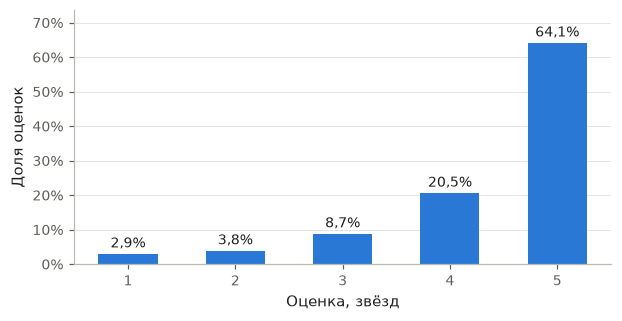

→ ml/reports/figures/01_ratings_distribution.png
4–5 звёзд: 84,6%, 1–2 звезды: 6,7%


In [3]:
dist = ratings["rating"].value_counts(normalize=True).sort_index()

fig, ax = plt.subplots(figsize=(W, 3.0))
ax.bar(dist.index.astype(str), dist.values, color=BLUE, width=0.55)
for x, v in zip(dist.index.astype(str), dist.values):
    ax.text(x, v + 0.01, pct(v), ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xlabel("Оценка, звёзд")
ax.set_ylabel("Доля оценок")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: pct(v, 0)))
ax.set_ylim(0, dist.max() * 1.15)
ax.grid(axis="x", visible=False)
save(fig, "01_ratings_distribution")
print(f"4–5 звёзд: {pct(dist.loc[[4, 5]].sum())}, 1–2 звезды: {pct(dist.loc[[1, 2]].sum())}")

**Вывод.** 84,6% оценок — 4–5 звёзд, 1–2 звезды — лишь 6,7%: люди оценивают в основном то, что им понравилось.
**Обосновывает:** предсказывать точное число звёзд бессмысленно — решаем задачу ранжирования, попаданием при проверке считаем 4–5★ (3.1).

## 3. Длинный хвост: оценок на книгу и на пользователя

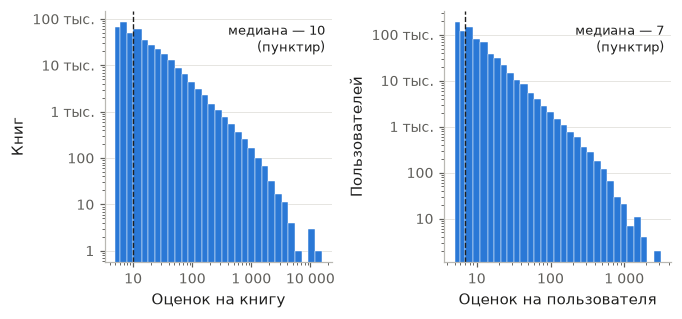

→ ml/reports/figures/02_long_tail.png


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(W, 3.0))
for ax, counts, xlabel, ylabel in [
    (axes[0], per_book, "Оценок на книгу", "Книг"),
    (axes[1], per_user, "Оценок на пользователя", "Пользователей"),
]:
    bins = np.unique(np.logspace(np.log10(5), np.log10(counts.max() + 1), 32).astype(int))
    ax.hist(counts, bins=bins, color=BLUE, edgecolor="white", linewidth=0.3)
    ax.set_xscale("log"); ax.set_yscale("log")
    med = counts.median()
    ax.axvline(med, color=INK, linestyle="--", linewidth=0.9)
    ax.text(0.97, 0.95, f"медиана — {ru(med)}\n(пунктир)", transform=ax.transAxes, ha="right", va="top",
            fontsize=8.5, color=INK)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: ru(v)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: ru_short(v)))
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "02_long_tail")

In [5]:
def top_share(counts, q):
    s = counts.sort_values(ascending=False)
    return s.iloc[: max(1, int(len(s) * q))].sum() / s.sum()

rows = []
for name, counts in [("книги", per_book), ("пользователи", per_user)]:
    rows.append({
        "": name,
        "медиана": ru(counts.median()),
        "90-й процентиль": ru(counts.quantile(0.9)),
        "максимум": ru(counts.max()),
        "с 5–9 оценками": pct((counts < 10).mean()),
        "доля оценок у топ-1%": pct(top_share(counts, 0.01)),
        "у топ-10%": pct(top_share(counts, 0.10)),
        "у топ-20%": pct(top_share(counts, 0.20)),
    })
pd.DataFrame(rows).style.hide(axis="index")

,медиана,90-й процентиль,максимум,с 5–9 оценками,доля оценок у топ-1%,у топ-10%,у топ-20%
книги,10,40,15 448,"49,6%","22,2%","53,0%","66,2%"
пользователи,7,20,3 118,"66,7%","14,5%","40,4%","53,6%"


**Вывод.** Оба распределения — длинный хвост (в лог-масштабе почти прямые): топ-10% книг собирают 53% оценок, у половины книг
и у двух третей пользователей — всего 5–9 оценок. **Обосновывает:** Popularity будет рекомендовать узкий круг книг (низкий Coverage);
для хвоста нужен content-based; эксперимент «качество в зависимости от числа оценок пользователя» (3.7) актуален — таких пользователей большинство.

## 4. Оценки по годам и книги по годам издания

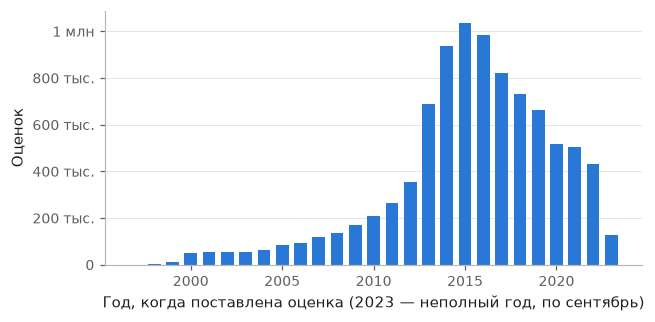

→ ml/reports/figures/03_ratings_by_year.png
Оценок по месяцам с октября 2022 (видно обрыв сбора данных):
10.22: 35 414 11.22: 32 288 12.22: 31 561 01.23: 37 935 02.23: 32 450 03.23: 33 421 04.23: 15 272 05.23: 4 181 06.23: 1 257 07.23: 830 08.23: 679 09.23: 51

Пик — 2015 (1 036 994 оценок). Оценок с 2015 года: 63,5%


In [6]:
by_year = ratings["dt"].dt.year.value_counts().sort_index()
by_year = by_year[by_year.index >= 1997]

fig, ax = plt.subplots(figsize=(W, 3.0))
ax.bar(by_year.index, by_year.values, color=BLUE, width=0.7)
ax.set_xlabel("Год, когда поставлена оценка (2023 — неполный год, по сентябрь)")
ax.set_ylabel("Оценок")
ax.yaxis.set_major_formatter(FuncFormatter(ru_short))
ax.set_xticks(range(2000, 2024, 5))
ax.grid(axis="x", visible=False)
save(fig, "03_ratings_by_year")

monthly_2023 = ratings.loc[ratings["dt"] >= "2022-10-01", "dt"].dt.to_period("M").value_counts().sort_index()
print("Оценок по месяцам с октября 2022 (видно обрыв сбора данных):")
print(" ".join(f"{p.strftime('%m.%y')}: {ru(n)}" for p, n in monthly_2023.items()))
peak = by_year.idxmax()
print(f"\nПик — {peak} ({ru(by_year[peak])} оценок). Оценок с 2015 года: {pct((ratings['dt'] >= '2015-01-01').mean())}")

**Вывод.** Активность растёт с 2012 года, пик — 2015 (1 млн оценок), потом спад; 63,5% оценок поставлены с 2015 года.
В 2023 году сбор данных фактически обрывается в апреле (с мая — сотни оценок в месяц). **Обосновывает:** выбор даты разбиения (п. 8):
последний полноценный месяц — март 2023, тестовый период не стоит делать коротким.

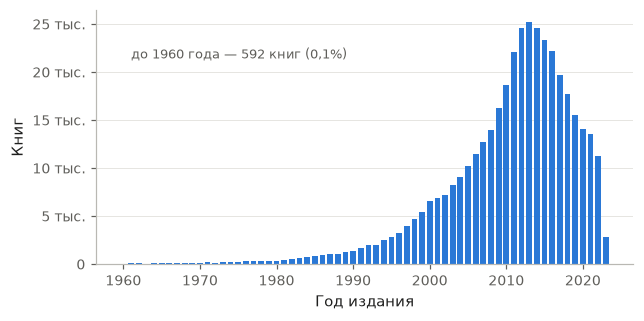

→ ml/reports/figures/04_books_by_pub_year.png
Доля книг по десятилетиям издания: 1970-е — 0,6%, 1980-е — 2,0%, 1990-е — 7,5%, 2000-е — 25,7%, 2010-е — 53,4%, 2020-е — 10,5%
Год неизвестен: 2,0%. Изданы с 2000 года: 89,5%


In [7]:
pub = books["year"].dropna().astype(int)
shown = pub[pub >= 1960].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(W, 3.0))
ax.bar(shown.index, shown.values, color=BLUE, width=0.75)
ax.set_xlabel("Год издания")
ax.set_ylabel("Книг")
ax.yaxis.set_major_formatter(FuncFormatter(ru_short))
ax.set_xticks(range(1960, 2030, 10))
ax.grid(axis="x", visible=False)
ax.text(1961, shown.max() * 0.85, f"до 1960 года — {ru((pub < 1960).sum())} книг ({pct((pub < 1960).mean())})",
        fontsize=8.5, color=MUTED)
save(fig, "04_books_by_pub_year")

decades = (pub // 10 * 10).value_counts(normalize=True).sort_index()
print("Доля книг по десятилетиям издания:",
      ", ".join(f"{d}-е — {pct(s)}" for d, s in decades[decades.index >= 1970].items()))
print(f"Год неизвестен: {pct(books['year'].isna().mean())}. Изданы с 2000 года: {pct((pub >= 2000).mean())}")

**Вывод.** 89,5% книг изданы с 2000 года, пик — 2012–2014; до 1960 года — 0,1%. Каталог современный.
**Обосновывает:** выбор датасета (1.1) — в отличие от Goodbooks-10k (популярные книги до 2017 года) здесь есть свежие книги и нон-фикшн.

## 5. Разделы онбординга: книги и оценки

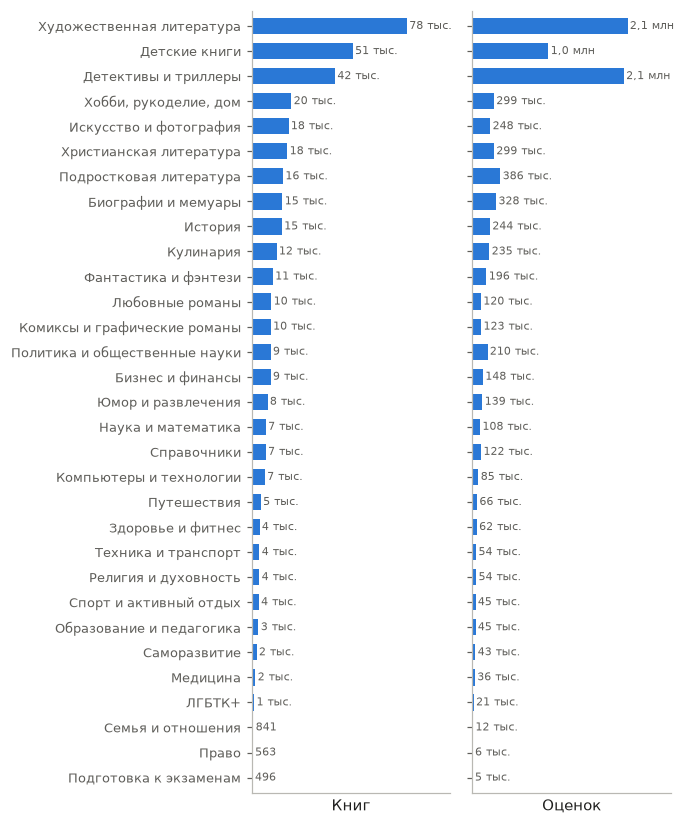

→ ml/reports/figures/05_onboarding_sections.png
Разделов: 31. Три крупнейших — 43,2% книг раздела онбординга. Самый маленький: Подготовка к экзаменам — 496 книг.


In [8]:
sec_books = books["onboarding_section"].value_counts()
sec_ratings = (ratings.merge(books[["parent_asin", "onboarding_section"]], on="parent_asin")
               .groupby("onboarding_section").size().reindex(sec_books.index))
labels = [SECTION_RU.get(s, s) for s in sec_books.index]
y = np.arange(len(sec_books))[::-1]

fig, axes = plt.subplots(1, 2, figsize=(W, 7.6), sharey=True)
for ax, values, xlabel in [(axes[0], sec_books, "Книг"), (axes[1], sec_ratings, "Оценок")]:
    ax.barh(y, values.values, color=BLUE, height=0.65)
    for yi, v in zip(y, values.values):
        ax.text(v + values.max() * 0.015, yi, ru_short(v), va="center", fontsize=7.5, color=MUTED)
    ax.set_xlabel(xlabel)
    ax.set_xticks([])  # значения подписаны у столбцов
    ax.set_xlim(0, values.max() * 1.28)
    ax.set_ylim(-0.6, len(y) - 0.4)
    ax.grid(False)
axes[0].set_yticks(y)
axes[0].set_yticklabels(labels, fontsize=8.5)
fig.tight_layout()
save(fig, "05_onboarding_sections")

top3 = sec_books.head(3).sum() / sec_books.sum()
print(f"Разделов: {len(sec_books)}. Три крупнейших — {pct(top3)} книг раздела онбординга. "
      f"Самый маленький: {SECTION_RU.get(sec_books.index[-1])} — {ru(sec_books.iloc[-1])} книг.")

In [9]:
# Глубина дерева и подтемы (п. 5 плана в 1.4)
depth = books["categories"].map(len)
cat3_per_section = books.dropna(subset=["onboarding_section", "cat3"]).groupby("onboarding_section")["cat3"].nunique()
programming = books["categories"].map(lambda c: any("Programming" in x for x in c))
javascript = books["title"].fillna("").str.contains("javascript", case=False)
print(f"Длина пути категорий (с корнем): " + ", ".join(f"{k} — {pct(v)}" for k, v in depth.value_counts(normalize=True).sort_index().items()))
print(f"Подразделов (уровень 3) на раздел онбординга: медиана {ru(cat3_per_section.median())}, "
      f"от {cat3_per_section.min()} до {cat3_per_section.max()}")
print(f"Книг с Programming в категориях: {ru(programming.sum())}; со словом JavaScript в названии: {ru(javascript.sum())}")

Длина пути категорий (с корнем): 0 — 1,8%, 2 — 1,4%, 3 — 96,3%, 4 — 0,3%, 5 — 0,2%, 6 — 0,0%
Подразделов (уровень 3) на раздел онбординга: медиана 13, от 2 до 26
Книг с Programming в категориях: 1 763; со словом JavaScript в названии: 111


**Вывод.** 31 тематический раздел; три крупнейших (художественная литература, детские, детективы) — 43% книг. Разделы сильно неравны —
от 78 тыс. до 500 книг, а оценок на книгу у детективов в 2,5 раза больше, чем у детских. Дерево Amazon неглубокое: у 96% книг два уровня под корнем,
в разделе в среднем 13 подразделов. **Обосновывает:** крупные разделы в онбординге нужно делить на подтемы кластерами (2.3);
IT-тематика представлена слабо (1,8 тыс. книг по программированию, 111 — про JavaScript).

## 6. Полнота метаданных

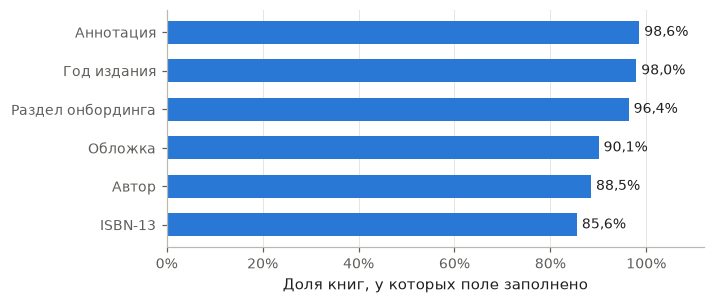

→ ml/reports/figures/06_metadata_completeness.png
Длина аннотации (features), символов: медиана 939, 10-й процентиль 294, 90-й — 1 887. Короче 200 символов: 5,6% книг с аннотацией.
Склеенных карточек (2+ изданий): 12,8%


In [10]:
features_len = books["features"].map(lambda f: len(" ".join(f)))
completeness = pd.Series({
    "Аннотация": (features_len > 0).mean(),
    "Автор": books["author"].notna().mean(),
    "Обложка": books["image"].notna().mean(),
    "Год издания": books["year"].notna().mean(),
    "ISBN-13": books["isbn13"].notna().mean(),
    "Раздел онбординга": books["onboarding_section"].notna().mean(),
}).sort_values()

fig, ax = plt.subplots(figsize=(W, 2.8))
ax.barh(completeness.index, completeness.values, color=BLUE, height=0.6)
for i, v in enumerate(completeness.values):
    ax.text(v + 0.01, i, pct(v), va="center", fontsize=9, color=INK)
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: pct(v, 0) if v <= 1 else ""))
ax.set_xlabel("Доля книг, у которых поле заполнено")
ax.grid(axis="y", visible=False)
save(fig, "06_metadata_completeness")

ann = features_len[features_len > 0]
print(f"Длина аннотации (features), символов: медиана {ru(ann.median())}, 10-й процентиль {ru(ann.quantile(.1))}, "
      f"90-й — {ru(ann.quantile(.9))}. Короче 200 символов: {pct((ann < 200).mean())} книг с аннотацией.")
print(f"Склеенных карточек (2+ изданий): {pct((books['n_editions'] > 1).mean())}")

**Вывод.** Аннотация есть у 98,6% книг (медиана — 940 символов), год — у 98%, обложка — у 90%, автор — у 88,5%.
**Обосновывает:** content-based (TF-IDF, эмбеддинги) опирается на надёжный текст; для 10% книг без обложки нужен запасной вариант —
Open Library по ISBN (он есть у 86% книг) или заглушка (1.3, п. 8).

**Отзывы (п. 7 плана в 1.4)** — тексты отзывов (`raw/review_categories/Books.jsonl`, 20 ГБ) ещё не скачаны;
этот пункт EDA — на шаге модуля сводки отзывов (2.6.1, 3.6).

## 7. Воронка очистки

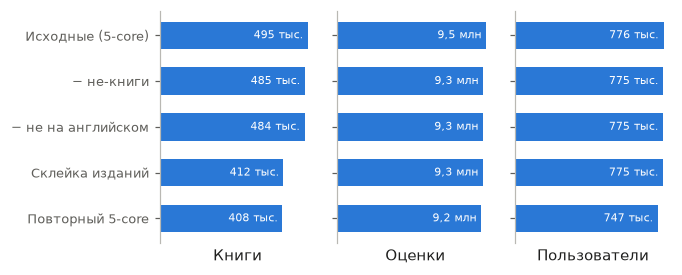

→ ml/reports/figures/07_cleaning_funnel.png
Итого осталось: книг 82,4%, оценок 96,6%, пользователей 96,2%


шаг,книг,оценок,пользователей
0. исходные данные (5-core),495 063,9 488 297,776 370
1. удалены не-книги,484 773,9 295 234,775 174
2. удалены книги не на английском,483 703,9 284 409,775 115
3. склеены издания,412 465,9 279 962,775 115
4. повторный 5-core (10 итер.),407 927,9 164 925,746 792


In [11]:
STEP_RU = ["Исходные (5-core)", "− не-книги", "− не на английском", "Склейка изданий", "Повторный 5-core"]
f = funnel.copy()
f.index = STEP_RU
y = np.arange(len(f))[::-1]

fig, axes = plt.subplots(1, 3, figsize=(W, 2.6), sharey=True)
for ax, col, title in [(axes[0], "книг", "Книги"), (axes[1], "оценок", "Оценки"), (axes[2], "пользователей", "Пользователи")]:
    ax.barh(y, f[col].values, color=BLUE, height=0.6)
    for yi, v in zip(y, f[col].values):
        ax.text(v * 0.97, yi, ru_short(v), va="center", ha="right", fontsize=7.5, color="white")
    ax.set_xlabel(title)
    ax.set_xticks([])
    ax.grid(False)
    ax.spines["bottom"].set_visible(False)
axes[0].set_yticks(y)
axes[0].set_yticklabels(STEP_RU, fontsize=8.5)
fig.tight_layout()
save(fig, "07_cleaning_funnel")

first, last = funnel.iloc[0], funnel.iloc[-1]
table = funnel.copy()
for col in ["книг", "оценок", "пользователей"]:
    table[col] = table[col].map(ru)
print(f"Итого осталось: книг {pct(last['книг'] / first['книг'])}, оценок {pct(last['оценок'] / first['оценок'])}, "
      f"пользователей {pct(last['пользователей'] / first['пользователей'])}")
table.style.hide(axis="index")

**Вывод.** Очистка убрала 18% карточек книг, но лишь 3,4% оценок: основное сокращение книг — склейка изданий (−71 тыс. карточек),
а не удаление; не-книги и неанглоязычные — около 2% книг. **Обосновывает:** очистка почти не теряет сигнал о вкусах пользователей,
а каталог становится чище (одна карточка на книгу).

## 8. Даты разбиения на обучение / валидацию / тест (к разделу 3.1)

Разбиение глобальное по времени: всё до даты валидации — обучение, между датами — валидация, после даты теста — тест.
Для каждой части:
- **с историей** — доля пользователей части, у которых есть оценки раньше её начала (только им коллаборативная фильтрация может что-то рекомендовать; остальные — холодный старт);
- **4–5★** — доля оценок, которые считаются попаданием при проверке (3.1);
- **на новые книги** — доля оценок на книги, у которых раньше начала части не было ни одной оценки (холодные книги).

In [12]:
user_first = ratings.groupby("user_id")["dt"].min()
book_first = ratings.groupby("parent_asin")["dt"].min()

def split_table(val_start, test_start):
    vs, ts = pd.Timestamp(val_start), pd.Timestamp(test_start)
    parts = [("обучение", None, vs), ("валидация", vs, ts), ("тест", ts, None)]
    rows = []
    for name, start, end in parts:
        mask = pd.Series(True, index=ratings.index)
        if start is not None:
            mask &= ratings["dt"] >= start
        if end is not None:
            mask &= ratings["dt"] < end
        part = ratings[mask]
        users = part["user_id"].unique()
        row = {
            "часть": name,
            "период": f"{'' if start is None else f'{start:%d.%m.%Y}'} — {'' if end is None else f'{end:%d.%m.%Y}'}".strip(" —"),
            "оценок": ru(len(part)), "% оценок": pct(len(part) / N_RATINGS),
            "пользователей": ru(len(users)), "книг": ru(part["parent_asin"].nunique()),
        }
        if start is not None:
            row["с историей"] = pct((user_first.loc[users] < start).mean())
            row["4–5★"] = pct((part["rating"] >= 4).mean())
            row["на новые книги"] = pct((part["parent_asin"].map(book_first) >= start).mean())
        rows.append(row)
    return pd.DataFrame(rows).fillna("")

q90, q95 = ratings["dt"].quantile([0.90, 0.95])
VARIANTS = {
    "А. Календарные годы: валидация — 2021, тест — с 2022": ("2021-01-01", "2022-01-01"),
    "Б. Полугодия: валидация — I пол. 2022, тест — с июля 2022": ("2022-01-01", "2022-07-01"),
    f"В. По доле оценок 90 / 5 / 5%: даты {q90:%m.%Y} и {q95:%m.%Y} (округлены до месяца)":
        (q90.to_period("M").start_time, q95.to_period("M").start_time),
}
for name, (vs, ts) in VARIANTS.items():
    print(name)
    display(split_table(vs, ts).style.hide(axis="index"))

А. Календарные годы: валидация — 2021, тест — с 2022


часть,период,оценок,% оценок,пользователей,книг,с историей,4–5★,на новые книги
обучение,01.01.2021,8 104 198,"88,4%",729 654,378 508,,,
валидация,01.01.2021 — 01.01.2022,504 924,"5,5%",163 668,106 825,"93,8%","86,2%","40,8%"
тест,01.01.2022,555 803,"6,1%",153 708,107 669,"95,4%","86,3%","45,7%"


Б. Полугодия: валидация — I пол. 2022, тест — с июля 2022


часть,период,оценок,% оценок,пользователей,книг,с историей,4–5★,на новые книги
обучение,01.01.2022,8 609 122,"93,9%",739 725,392 939,,,
валидация,01.01.2022 — 01.07.2022,220 005,"2,4%",89 707,62 716,"96,5%","85,9%","36,2%"
тест,01.07.2022,335 798,"3,7%",107 925,78 267,"96,4%","86,7%","41,8%"


В. По доле оценок 90 / 5 / 5%: даты 04.2021 и 03.2022 (округлены до месяца)


часть,период,оценок,% оценок,пользователей,книг,с историей,4–5★,на новые книги
обучение,01.04.2021,8 240 977,"89,9%",733 059,382 316,,,
валидация,01.04.2021 — 01.03.2022,446 757,"4,9%",150 484,98 434,"94,8%","86,2%","40,8%"
тест,01.03.2022,477 191,"5,2%",137 666,97 831,"95,7%","86,4%","45,1%"


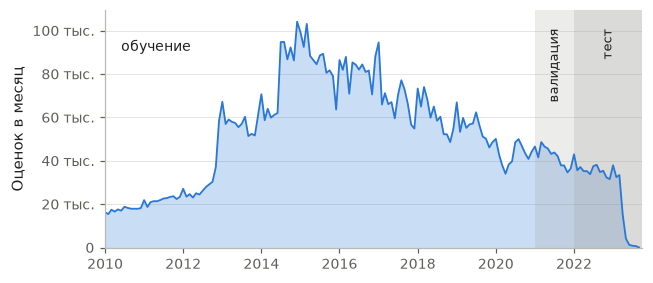

→ ml/reports/figures/08_time_split.png


In [13]:
RECOMMENDED = "А. Календарные годы: валидация — 2021, тест — с 2022"
vs, ts = map(pd.Timestamp, VARIANTS[RECOMMENDED])
monthly = ratings.loc[ratings["dt"] >= "2010-01-01", "dt"].dt.to_period("M").value_counts().sort_index()
x = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(W, 2.8))
ax.fill_between(x, monthly.values, color=BLUE, alpha=0.25, linewidth=0)
ax.plot(x, monthly.values, color=BLUE, linewidth=1.2)
end = x.max() + pd.offsets.MonthEnd(1)
ax.axvspan(vs, ts, color="#9a9994", alpha=0.18, linewidth=0)
ax.axvspan(ts, end, color="#9a9994", alpha=0.36, linewidth=0)
top = monthly.max()
ax.text(x.min() + pd.Timedelta(days=150), top * 0.92, "обучение", ha="left", va="top", fontsize=9, color=INK)
for a, b, label in [(vs, ts, "валидация"), (ts, end, "тест")]:
    ax.text(a + (b - a) / 2, top * 0.97, label, ha="center", va="top", rotation=90, fontsize=8.5, color=INK)
ax.set_ylabel("Оценок в месяц")
ax.yaxis.set_major_formatter(FuncFormatter(ru_short))
ax.set_xlim(x.min(), end)
ax.set_ylim(0, top * 1.05)
ax.grid(axis="x", visible=False)
save(fig, "08_time_split")

**Предложение (черновик) — вариант А:** обучение — до 01.01.2021 (88% оценок), валидация — 2021 год (5,5%), тест — с 01.01.2022 (6,1%;
фактически по апрель 2023). Валидация и тест близки по объёму (~0,5 млн оценок, ~150–160 тыс. пользователей), даты наглядны для текста диплома.
Вариант Б даёт слишком маленькую валидацию (2,4%), вариант В почти совпадает с А.

**Важная находка:** у 94–95% пользователей валидации и теста есть история в обучении — проверять коллаборативную фильтрацию корректно.
Но **41–46% оценок валидации и теста — на книги, у которых раньше не было ни одной оценки** (новинки). Коллаборативные модели такие книги
не порекомендуют в принципе. **Обосновывает:** гибрид с content-based (3.3); при проверке нужно решить — считать такие книги в тесте
(честно, но занижает CF) или отдельно отчитываться по «старым» и «новым» книгам.

## Сводка: что показал EDA и что это обосновывает

In [14]:
from IPython.display import Markdown
rows = [
    ("Объём и разреженность", f"{ru(N_BOOKS)} книг, {ru(N_USERS)} польз., {ru(N_RATINGS)} оценок; плотность {ru(100 * density, 4)}%",
     "Матрица почти пустая → матричная факторизация (ALS), гибриды, content-based"),
    ("Оценки 1–5", f"4–5★ — {pct(dist.loc[[4, 5]].sum())}",
     "Оценка — сигнал «понравилось», задача ранжирования; попадание = 4–5★"),
    ("Длинный хвост", f"медиана {ru(per_book.median())} оценок на книгу, {ru(per_user.median())} на пользователя; "
     f"топ-10% книг — {pct(top_share(per_book, 0.1))} оценок",
     "Большинство книг и пользователей — с малой историей → холодный старт, content-based; Popularity даст низкий coverage"),
    ("Годы", f"оценок с 2015 — {pct((ratings['dt'] >= '2015-01-01').mean())}; книг изданы с 2000 — {pct((pub >= 2000).mean())}",
     "Каталог современный; дата разбиения — см. п. 8"),
    ("Разделы", f"{len(sec_books)} разделов онбординга; три крупнейших — {pct(top3)} книг",
     "Дерево тем для онбординга; подтемы — кластерами (2.3)"),
    ("Метаданные", f"аннотация — {pct(completeness['Аннотация'])}, обложка — {pct(completeness['Обложка'])}, "
     f"автор — {pct(completeness['Автор'])}",
     "Content-based надёжен; обложки — fallback на Open Library по ISBN (1.3, п. 8)"),
    ("Воронка", f"осталось {pct(last['книг'] / first['книг'])} книг, {pct(last['оценок'] / first['оценок'])} оценок",
     "Прозрачность подготовки данных"),
    ("Разбиение", RECOMMENDED, "Предложение для 3.1 (черновик)"),
]
Markdown("| Что смотрели | Цифры | Что обосновывает |\n|---|---|---|\n" + "\n".join(f"| {a} | {b} | {c} |" for a, b, c in rows))

| Что смотрели | Цифры | Что обосновывает |
|---|---|---|
| Объём и разреженность | 407 927 книг, 746 792 польз., 9 164 925 оценок; плотность 0,0030% | Матрица почти пустая → матричная факторизация (ALS), гибриды, content-based |
| Оценки 1–5 | 4–5★ — 84,6% | Оценка — сигнал «понравилось», задача ранжирования; попадание = 4–5★ |
| Длинный хвост | медиана 10 оценок на книгу, 7 на пользователя; топ-10% книг — 53,0% оценок | Большинство книг и пользователей — с малой историей → холодный старт, content-based; Popularity даст низкий coverage |
| Годы | оценок с 2015 — 63,5%; книг изданы с 2000 — 89,5% | Каталог современный; дата разбиения — см. п. 8 |
| Разделы | 31 разделов онбординга; три крупнейших — 43,2% книг | Дерево тем для онбординга; подтемы — кластерами (2.3) |
| Метаданные | аннотация — 98,6%, обложка — 90,1%, автор — 88,5% | Content-based надёжен; обложки — fallback на Open Library по ISBN (1.3, п. 8) |
| Воронка | осталось 82,4% книг, 96,6% оценок | Прозрачность подготовки данных |
| Разбиение | А. Календарные годы: валидация — 2021, тест — с 2022 | Предложение для 3.1 (черновик) |